# BÀI TẬP NÂNG CAO với mô hình SARIMA – Dataset 2 (AirPassengers)

## Bước 4. ACF / PACF → xác định (p, q, P, Q)

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
S = 12           # chu kỳ mùa vụ
TEST_SIZE = 24   # 2 năm cuối làm tập kiểm tra

df = pd.read_csv(URL)
df.columns = ["Month", "Passengers"]
df["Month"] = pd.to_datetime(df["Month"])
y = df.set_index("Month")["Passengers"].asfreq("MS")
train, test = y.iloc[:-TEST_SIZE], y.iloc[-TEST_SIZE:]
print(y.shape)
y.head()

(144,)


Month
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64

In [2]:
y_d1_D1 = y.diff(1).diff(S).dropna()

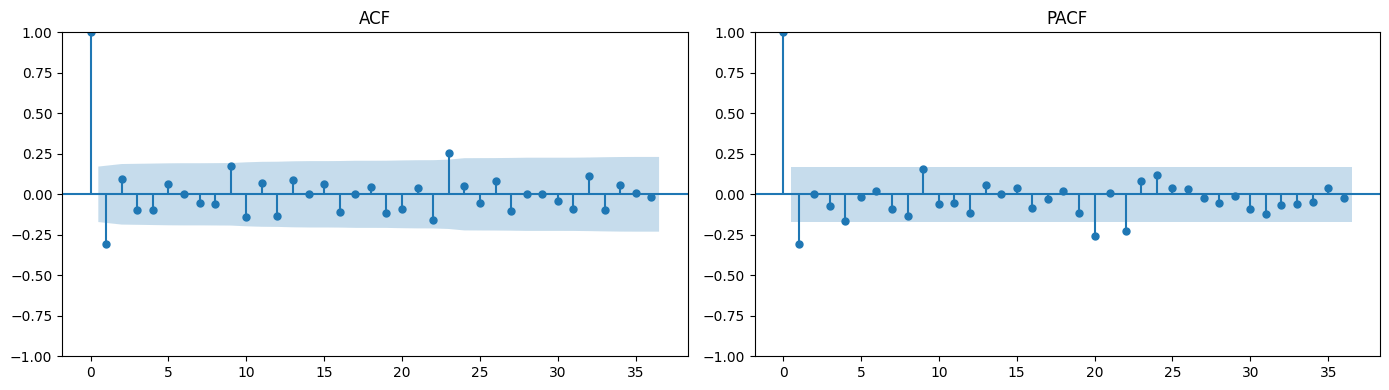

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(y_d1_D1, lags=36, ax=ax[0])
plot_pacf(y_d1_D1, lags=36, ax=ax[1], method="ywm")
ax[0].set_title("ACF"); ax[1].set_title("PACF")
plt.tight_layout(); plt.show()

**Đọc biểu đồ:**
- ACF có spike nổi bật tại lag 1 → **q = 1**
- ACF có spike nổi bật tại lag 12 → **Q = 1**
- PACF giảm dần, không cắt rõ → **p = 0, P = 0**

⇒ Mô hình đề xuất: **SARIMA(0,1,1)(0,1,1)₁₂**